<a href="https://colab.research.google.com/github/timokoya/PhD-Decentralised-MARS/blob/main/Pistonball_8_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pettingzoo
!pip install stable-baselines3[extra]
!pip install supersuit
!pip install pymunk

#!pip install 'imageio==2.4.1' # A specific version might be needed for moviepy compat
#!pip install 'imageio-ffmpeg'
#!pip install 'moviepy'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.5/668.5 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 67.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 21.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.9/156.9 kB 6.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.6/50.6 kB 5.5 MB/s eta 0:00:00
  Created wheel for tinyscaler: filename=tinyscaler-1.2.8-cp313-cp313-linux_x86_64.whl size=544598 sha256=3f33b9eb95a73be3818b9b6c25e8ee8194c4355e9f7599f7f0e178622532373c
  Stored in directory: /root/.cache/pip/wheels/bc/89/67/0390e0b26cea0ca867b0117174f55f04220af93cfdd19359ae
Successfully built tinyscaler
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 25.3 MB/s eta 0:00:00


Training on cuda with PPO+LSTM with Aux Task
Run Name: Pistonball_LSTM_Plotting_1790730662

--- Generating video at Global Step 1024 ---


--- Video generation complete. Resuming training... ---


--- Generating video at Global Step 11264 ---


--- Video generation complete. Resuming training... ---


--- Generating video at Global Step 21504 ---


--- Video generation complete. Resuming training... ---


--- Generating video at Global Step 31744 ---


--- Video generation complete. Resuming training... ---


--- Generating video at Global Step 41984 ---


--- Video generation complete. Resuming training... ---


--- Training Complete ---

--- Generating final training plots ---

Training plots saved to ./runs/Pistonball_LSTM_Plotting_1790730662/plots/training_metrics_plot.png


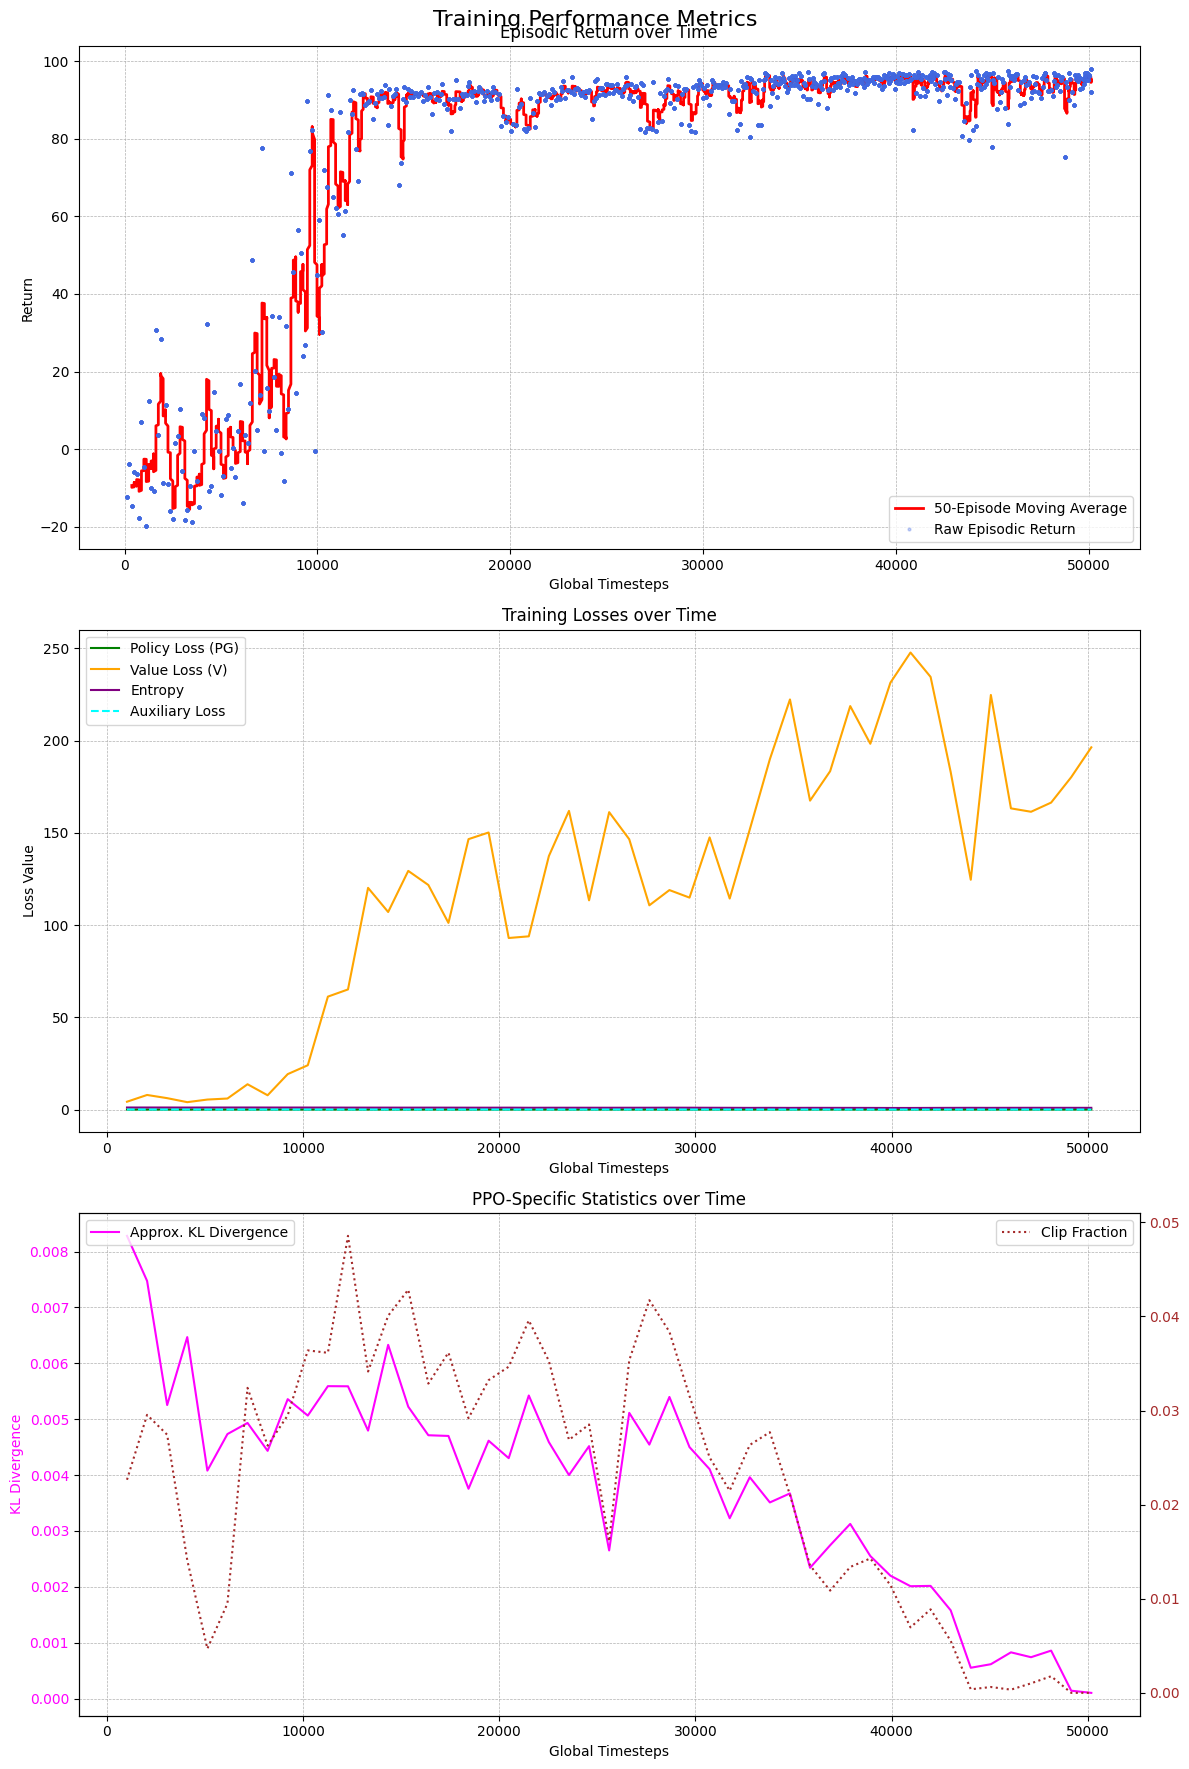

In [ ]:
"""
Pistonball-8-v2
PPO on Pistonball with an LSTM agent, console logging, sequential video rendering,
and final metric plotting for analysis.
"""
# --- Basic Imports ---
import os
import random
import time
from collections import deque
from base64 import b64encode # For video rendering

# --- ML Imports ---
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions.categorical import Categorical

# --- Environment Imports ---
from pettingzoo.butterfly import pistonball_v6
from supersuit import color_reduction_v0, frame_stack_v1, resize_v1

# --- Colab Rendering & Plotting Imports ---
import imageio
from IPython.display import HTML, display, clear_output
import matplotlib.pyplot as plt


class Agent(nn.Module):
    def __init__(self, num_actions, lstm_hidden_size=256, num_lstm_layers=1,
                 use_aux_task=False, aux_target_dim=1):
        super().__init__()
        self.lstm_hidden_size = lstm_hidden_size
        self.num_lstm_layers = num_lstm_layers
        self.use_aux_task = use_aux_task
        self.aux_target_dim = aux_target_dim

        self.cnn = nn.Sequential(
            self._layer_init(nn.Conv2d(4, 32, 3, padding=1)),
            nn.MaxPool2d(2), nn.ReLU(),
            self._layer_init(nn.Conv2d(32, 64, 3, padding=1)),
            nn.MaxPool2d(2), nn.ReLU(),
            self._layer_init(nn.Conv2d(64, 128, 3, padding=1)),
            nn.MaxPool2d(2), nn.ReLU(),
            nn.Flatten(),
        )
        self.lstm_input_size = 128 * 8 * 8

        self.lstm = nn.LSTM(
            self.lstm_input_size, self.lstm_hidden_size,
            num_layers=self.num_lstm_layers, batch_first=True
        )

        self.actor = self._layer_init(nn.Linear(self.lstm_hidden_size, num_actions), std=0.01)
        self.critic = self._layer_init(nn.Linear(self.lstm_hidden_size, 1))

        if self.use_aux_task:
            self.aux_predictor = self._layer_init(nn.Linear(self.lstm_hidden_size, self.aux_target_dim))
        else:
            self.aux_predictor = None

    def _layer_init(self, layer, std=np.sqrt(2), bias_const=0.0):
        torch.nn.init.orthogonal_(layer.weight, std)
        torch.nn.init.constant_(layer.bias, bias_const)
        return layer

    def get_value(self, x, hx, cx):
        cnn_out = self.cnn(x / 255.0)
        lstm_in = cnn_out.unsqueeze(1)

        if hx.dim() == 2 and self.num_lstm_layers == 1:
            hx_lstm, cx_lstm = hx.unsqueeze(0), cx.unsqueeze(0)
        else:
            hx_lstm = hx.view(self.num_lstm_layers, -1, self.lstm_hidden_size)
            cx_lstm = cx.view(self.num_lstm_layers, -1, self.lstm_hidden_size)

        lstm_out, (next_hx, next_cx) = self.lstm(lstm_in, (hx_lstm, cx_lstm))
        value_out = self.critic(lstm_out.squeeze(1))

        if self.num_lstm_layers == 1:
            next_hx, next_cx = next_hx.squeeze(0), next_cx.squeeze(0)
        return value_out, next_hx, next_cx

    def get_action_and_value(self, x, hx, cx, action=None):
        cnn_out = self.cnn(x / 255.0)
        lstm_in = cnn_out.unsqueeze(1)

        if hx.dim() == 2 and self.num_lstm_layers == 1:
            hx_lstm, cx_lstm = hx.unsqueeze(0), cx.unsqueeze(0)
        else:
            hx_lstm = hx.view(self.num_lstm_layers, -1, self.lstm_hidden_size)
            cx_lstm = cx.view(self.num_lstm_layers, -1, self.lstm_hidden_size)

        lstm_out, (next_hx, next_cx) = self.lstm(lstm_in, (hx_lstm, cx_lstm))
        hidden_features = lstm_out.squeeze(1)

        logits = self.actor(hidden_features)
        probs = Categorical(logits=logits)
        if action is None:
            action = probs.sample()

        log_prob_action = probs.log_prob(action)
        entropy = probs.entropy()
        value = self.critic(hidden_features)

        aux_prediction = None
        if self.use_aux_task and self.aux_predictor is not None:
            aux_prediction = self.aux_predictor(hidden_features)

        if self.num_lstm_layers == 1:
            next_hx, next_cx = next_hx.squeeze(0), next_cx.squeeze(0)

        return action, log_prob_action, entropy, value, aux_prediction, next_hx, next_cx


def batchify_obs(obs_dict, device):
    if not obs_dict:
        raise ValueError("batchify_obs received an empty observation dictionary. Environment may need reset.")
    obs_list = [obs_dict[a] for a in obs_dict]
    obs_np = np.stack(obs_list, axis=0)
    obs_permuted = obs_np.transpose(0, 3, 1, 2)
    obs_tensor = torch.tensor(obs_permuted, dtype=torch.float32).to(device)
    return obs_tensor

def batchify_rewards_or_dones(data_dict, possible_agents_list, device, dtype=torch.float32):
    batch = [data_dict.get(agent_id, 0) for agent_id in possible_agents_list]
    return torch.tensor(batch, dtype=dtype).to(device)

def unbatchify(x, env):
    x_cpu = x.cpu().numpy()
    return {agent_id: x_cpu[i] for i, agent_id in enumerate(env.possible_agents)}

def calculate_aux_targets(next_obs_batch, frame_size=(64,64), patch_size=16, device="cpu"):
    if torch.all(next_obs_batch == 0):
        return torch.zeros(next_obs_batch.shape[0], 1).to(device)

    latest_frames = next_obs_batch[:, -1, :, :]
    H, W = frame_size
    center_h, center_w = H // 2, W // 2
    patch_half = patch_size // 2
    start_h, end_h = max(0, center_h - patch_half), min(H, center_h + patch_half)
    start_w, end_w = max(0, center_w - patch_half), min(W, center_w + patch_half)

    central_patches = latest_frames[:, start_h:end_h, start_w:end_w]
    targets = torch.mean(central_patches / 255.0, dim=(1, 2))
    return targets.unsqueeze(1)

def get_initial_lstm_states(num_agents_local, num_layers, hidden_size, dev):
    shape = (num_agents_local, hidden_size) if num_layers == 1 else (num_agents_local, num_layers, hidden_size)
    h = torch.zeros(shape).to(dev)
    c = torch.zeros(shape).to(dev)
    return h, c

def generate_and_display_video(agent_model, video_env_params, video_dir, current_step):
    print(f"\n--- Generating video at Global Step {current_step} ---")

    temp_env = pistonball_v6.parallel_env(render_mode="rgb_array", continuous=False, max_cycles=video_env_params['max_cycles'])
    temp_env = color_reduction_v0(temp_env); temp_env = resize_v1(temp_env, *video_env_params['frame_size']); temp_env = frame_stack_v1(temp_env, video_env_params['stack_size'])

    video_path = os.path.join(video_dir, f"step_{current_step}.mp4")

    # FIX 1: Integer constraint for seeding to prevent TypeError
    frames = []; obs_dict, _ = temp_env.reset(seed=random.randint(0, 1000000))
    hx, cx = get_initial_lstm_states(video_env_params['num_agents'], video_env_params['num_lstm_layers'], video_env_params['lstm_hidden_size'], device)

    initial_frame = temp_env.render()
    if initial_frame is not None: frames.append(initial_frame)

    agent_model.eval()
    while temp_env.agents:
        obs_tensor = batchify_obs(obs_dict, device)
        with torch.no_grad():
            actions, _, _, _, _, hx, cx = agent_model.get_action_and_value(obs_tensor, hx, cx)

        obs_dict, _, terms, truncs, _ = temp_env.step(unbatchify(actions, temp_env))

        frame = temp_env.render()
        if frame is not None: frames.append(frame)

        done_flags = torch.zeros(video_env_params['num_agents'], dtype=torch.bool).to(device)
        for i, agent_id in enumerate(video_env_params['possible_agents_list']):
            done_flags[i] = terms.get(agent_id, False) or truncs.get(agent_id, False)
        done_mask = (1.0 - done_flags.float())
        mask_shape = (video_env_params['num_agents'], 1) if video_env_params['num_lstm_layers'] == 1 else (video_env_params['num_agents'], 1, 1)
        hx, cx = hx * done_mask.view(mask_shape).expand_as(hx), cx * done_mask.view(mask_shape).expand_as(cx)

    temp_env.close()

    if frames:
        imageio.mimsave(video_path, frames, fps=30)
        mp4 = open(video_path, 'rb').read()
        data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

        display(HTML(f"""<hr><h3>Agent Performance at Step {current_step}</h3>
                         <video width=400 controls autoplay loop><source src="{data_url}" type="video/mp4"></video>"""))
    else:
        print("No frames recorded for video generation.")
    print("--- Video generation complete. Resuming training... ---\n")

def save_training_plots(metrics_history, save_dir):
    """Generates and saves plots of training metrics, now robust to empty data."""
    print("\n--- Generating final training plots ---")

    fig, axs = plt.subplots(3, 1, figsize=(12, 18), tight_layout=True)
    fig.suptitle('Training Performance Metrics', fontsize=16)

    # 1. Episodic Return Plot
    if metrics_history['episodic_returns']:
        ep_steps, ep_returns = zip(*metrics_history['episodic_returns'])
        window_size = 50
        if len(ep_returns) >= window_size:
            moving_avg = np.convolve(ep_returns, np.ones(window_size)/window_size, mode='valid')
            axs[0].plot(ep_steps[window_size-1:], moving_avg, color='red', linewidth=2, label=f'{window_size}-Episode Moving Average')

        axs[0].plot(ep_steps, ep_returns, 'o', color='royalblue', markersize=2, alpha=0.3, label='Raw Episodic Return')
        axs[0].legend()
    else:
        axs[0].text(0.5, 0.5, 'No completed episodes to plot.', horizontalalignment='center', verticalalignment='center', transform=axs[0].transAxes)

    axs[0].set_title('Episodic Return over Time')
    axs[0].set_xlabel('Global Timesteps')
    axs[0].set_ylabel('Return')
    axs[0].grid(True, which='both', linestyle='--', linewidth=0.5)

    # 2. Losses Plot
    if metrics_history['update_steps']:
        loss_steps = metrics_history['update_steps']
        axs[1].plot(loss_steps, metrics_history['policy_loss'], label='Policy Loss (PG)', color='green')
        axs[1].plot(loss_steps, metrics_history['value_loss'], label='Value Loss (V)', color='orange')
        axs[1].plot(loss_steps, metrics_history['entropy_loss'], label='Entropy', color='purple')
        if metrics_history.get('aux_loss') and metrics_history['aux_loss'] is not None:
            axs[1].plot(loss_steps, metrics_history['aux_loss'], label='Auxiliary Loss', color='cyan', linestyle='--')
        axs[1].legend()
    else:
        axs[1].text(0.5, 0.5, 'No PPO updates were performed.', horizontalalignment='center', verticalalignment='center', transform=axs[1].transAxes)

    axs[1].set_title('Training Losses over Time')
    axs[1].set_xlabel('Global Timesteps')
    axs[1].set_ylabel('Loss Value')
    axs[1].grid(True, which='both', linestyle='--', linewidth=0.5)


    # 3. PPO-specific Stats Plot
    if metrics_history['update_steps']:
        loss_steps = metrics_history['update_steps']
        axs[2].plot(loss_steps, metrics_history['approx_kl'], label='Approx. KL Divergence', color='magenta')
        axs[2].tick_params(axis='y', labelcolor='magenta')
        axs[2].legend(loc='upper left')

        ax2_twin = axs[2].twinx()
        ax2_twin.plot(loss_steps, metrics_history['clip_fraction'], label='Clip Fraction', color='brown', linestyle=':')
        ax2_twin.tick_params(axis='y', labelcolor='brown')
        ax2_twin.legend(loc='upper right')
    else:
        axs[2].text(0.5, 0.5, 'No PPO updates were performed.', horizontalalignment='center', verticalalignment='center', transform=axs[2].transAxes)

    axs[2].set_title('PPO-Specific Statistics over Time')
    axs[2].set_xlabel('Global Timesteps')
    axs[2].set_ylabel('KL Divergence', color='magenta')
    axs[2].grid(True, which='both', linestyle='--', linewidth=0.5)

    plot_path = os.path.join(save_dir, "training_metrics_plot.png")
    plt.savefig(plot_path, dpi=300)
    print(f"\nTraining plots saved to {plot_path}")
    plt.show()
    plt.close()


if __name__ == "__main__":
    """ALGO PARAMS"""
    run_name = f"Pistonball_LSTM_Plotting_{int(time.time())}"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # FIX 3: Lowered value function coefficient to help prevent Value Loss explosion
    ent_coef = 0.01; vf_coef = 0.25; clip_coef = 0.2; gamma = 0.99; gae_lambda = 0.95
    ppo_batch_size = 256; num_ppo_epochs = 4
    learning_rate = 2.5e-4
    anneal_lr = True

    stack_size = 4; frame_size = (64, 64); max_cycles_env = 125
    total_timesteps = 50000; steps_per_rollout = 1024

    lstm_hidden_size = 256; num_lstm_layers = 1

    use_aux_task = True; aux_target_dim = 1; aux_loss_coef = 0.1; aux_patch_size = 16

    video_log_freq = 10000; last_video_log_step = 0
    base_dir = f"./runs/{run_name}"; video_dir = os.path.join(base_dir, "videos"); plot_dir = os.path.join(base_dir, "plots")
    os.makedirs(video_dir, exist_ok=True); os.makedirs(plot_dir, exist_ok=True)

    """ METRIC LOGGING SETUP """
    metrics_history = {
        'episodic_returns': [],
        'update_steps': [],
        'policy_loss': [],
        'value_loss': [],
        'entropy_loss': [],
        'approx_kl': [],
        'clip_fraction': [],
        'aux_loss': [] if use_aux_task else None,
    }

    """ ENV SETUP """
    env = pistonball_v6.parallel_env(render_mode="rgb_array", continuous=False, max_cycles=max_cycles_env)
    env = color_reduction_v0(env); env = resize_v1(env, *frame_size); env = frame_stack_v1(env, stack_size)
    num_agents = len(env.possible_agents)
    possible_agents_list = list(env.possible_agents); num_actions = env.action_space(possible_agents_list[0]).n

    """ LEARNER SETUP """
    agent = Agent(
        num_actions=num_actions, lstm_hidden_size=lstm_hidden_size, num_lstm_layers=num_lstm_layers,
        use_aux_task=use_aux_task, aux_target_dim=aux_target_dim
    ).to(device)
    optimizer = optim.Adam(agent.parameters(), lr=learning_rate, eps=1e-5)

    """ ROLLOUT BUFFER """
    rb_shape_prefix = (steps_per_rollout, num_agents)
    obs_shape = rb_shape_prefix + (stack_size,) + frame_size
    rb_obs = torch.zeros(obs_shape).to(device)
    rb_next_obs = torch.zeros_like(rb_obs)

    rb_actions = torch.zeros(rb_shape_prefix, dtype=torch.long).to(device)
    rb_logprobs = torch.zeros(rb_shape_prefix).to(device)
    rb_rewards = torch.zeros(rb_shape_prefix).to(device)
    rb_dones = torch.zeros(rb_shape_prefix).to(device)
    rb_values = torch.zeros(rb_shape_prefix).to(device)

    lstm_shape_suffix = (lstm_hidden_size,) if num_lstm_layers == 1 else (num_lstm_layers, lstm_hidden_size)
    lstm_buffer_shape = rb_shape_prefix + lstm_shape_suffix
    rb_core_hxs = torch.zeros(lstm_buffer_shape).to(device)
    rb_core_cxs = torch.zeros(lstm_buffer_shape).to(device)

    print(f"Training on {device} with PPO+LSTM{' with Aux Task' if use_aux_task else ''}"); print(f"Run Name: {run_name}")
    rollout_start_time = time.time()
    global_step = 0; num_episodes_done_total = 0

    current_env_obs_dict, info = env.reset(seed=42)
    current_core_hx, current_core_cx = get_initial_lstm_states(num_agents, num_lstm_layers, lstm_hidden_size, device)
    current_done_for_gae_bootstrap = torch.zeros(num_agents, dtype=torch.float32).to(device)

    # FIX 2: Manual Episodic Return Tracking Initializer
    agent_episode_rewards = {agent_id: 0.0 for agent_id in possible_agents_list}

    while global_step < total_timesteps:
        if anneal_lr:
            frac = 1.0 - (global_step - 1.0) / total_timesteps
            lrnow = frac * learning_rate
            optimizer.param_groups[0]["lr"] = lrnow

        agent.eval()

        for step_in_rollout in range(steps_per_rollout):
            global_step += 1

            current_obs_tensor = batchify_obs(current_env_obs_dict, device)
            rb_obs[step_in_rollout] = current_obs_tensor
            rb_core_hxs[step_in_rollout] = current_core_hx
            rb_core_cxs[step_in_rollout] = current_core_cx

            with torch.no_grad():
                actions_tensor, logprobs, _, values_tensor, _, hx_out, cx_out = \
                    agent.get_action_and_value(current_obs_tensor, current_core_hx, current_core_cx)

            rb_values[step_in_rollout] = values_tensor.flatten()
            rb_actions[step_in_rollout] = actions_tensor
            rb_logprobs[step_in_rollout] = logprobs

            next_env_obs_dict, rewards_dict, terms_dict, truncs_dict, infos_dict = env.step(unbatchify(actions_tensor, env))
            rb_rewards[step_in_rollout] = batchify_rewards_or_dones(rewards_dict, possible_agents_list, device)

            done_flags_s_tp1 = torch.zeros(num_agents, dtype=torch.bool).to(device)
            for i, agent_id in enumerate(possible_agents_list):
                is_terminated = terms_dict.get(agent_id, False)
                is_truncated = truncs_dict.get(agent_id, False)
                done_flags_s_tp1[i] = is_terminated or is_truncated

                # FIX 2: Manual Episodic Return Tracking Execution
                agent_episode_rewards[agent_id] += rewards_dict.get(agent_id, 0.0)

                if is_terminated or is_truncated:
                    num_episodes_done_total += 1
                    metrics_history['episodic_returns'].append((global_step, agent_episode_rewards[agent_id]))
                    agent_episode_rewards[agent_id] = 0.0 # Reset for the next episode

            rb_dones[step_in_rollout] = done_flags_s_tp1.float()

            if not next_env_obs_dict and done_flags_s_tp1.all():
                rb_next_obs[step_in_rollout] = torch.zeros_like(current_obs_tensor)
            else:
                rb_next_obs[step_in_rollout] = batchify_obs(next_env_obs_dict, device)

            current_done_for_gae_bootstrap = done_flags_s_tp1.float()

            if not env.agents:
                current_env_obs_dict, info = env.reset(seed=None)
                current_core_hx, current_core_cx = get_initial_lstm_states(num_agents, num_lstm_layers, lstm_hidden_size, device)
                current_done_for_gae_bootstrap.zero_()
            else:
                current_env_obs_dict = next_env_obs_dict
                done_mask = (1.0 - done_flags_s_tp1.float())
                mask_shape = (num_agents, 1) if num_lstm_layers == 1 else (num_agents, 1, 1)
                current_core_hx = hx_out * done_mask.view(mask_shape).expand_as(hx_out)
                current_core_cx = cx_out * done_mask.view(mask_shape).expand_as(cx_out)

        with torch.no_grad():
            last_obs_bootstrap_tensor = batchify_obs(current_env_obs_dict, device)
            next_value_bootstrap, _, _ = agent.get_value(last_obs_bootstrap_tensor, current_core_hx, current_core_cx)
            next_value_bootstrap = next_value_bootstrap.reshape(1, -1)

            rb_advantages = torch.zeros_like(rb_rewards)
            last_gae_lam = 0
            for t in reversed(range(steps_per_rollout)):
                if t == steps_per_rollout - 1:
                    nextnonterminal = 1.0 - current_done_for_gae_bootstrap
                    nextvalues = next_value_bootstrap
                else:
                    nextnonterminal = 1.0 - rb_dones[t]
                    nextvalues = rb_values[t + 1]

                delta = rb_rewards[t] + gamma * nextvalues * nextnonterminal - rb_values[t]
                rb_advantages[t] = last_gae_lam = delta + gamma * gae_lambda * nextnonterminal * last_gae_lam
            rb_returns = rb_advantages + rb_values

        b_obs = rb_obs.view(-1, stack_size, *frame_size)
        b_next_obs_for_aux = rb_next_obs.view(-1, stack_size, *frame_size)
        b_logprobs = rb_logprobs.view(-1)
        b_actions = rb_actions.view(-1)
        b_advantages = rb_advantages.view(-1)
        b_returns = rb_returns.view(-1)
        b_values = rb_values.view(-1)

        b_lstm_shape_suffix = (lstm_hidden_size,) if num_lstm_layers == 1 else (num_lstm_layers, lstm_hidden_size)
        b_core_hxs = rb_core_hxs.view(-1, *b_lstm_shape_suffix)
        b_core_cxs = rb_core_cxs.view(-1, *b_lstm_shape_suffix)

        b_aux_targets = calculate_aux_targets(b_next_obs_for_aux, frame_size, aux_patch_size, device) if use_aux_task else None

        agent.train()
        all_pg_loss, all_v_loss, all_ent_loss, all_approx_kl, all_clip_frac = [], [], [], [], []
        all_aux_loss = [] if use_aux_task else None

        total_transitions_in_rollout = b_obs.shape[0]
        indices = np.arange(total_transitions_in_rollout)
        b_advantages = (b_advantages - b_advantages.mean()) / (b_advantages.std() + 1e-8)

        for ppo_epoch in range(num_ppo_epochs):
            np.random.shuffle(indices)
            for start in range(0, total_transitions_in_rollout, ppo_batch_size):
                end = start + ppo_batch_size
                mb_indices = indices[start:end]

                _, newlogprob, entropy, newvalue, aux_predictions, _, _ = agent.get_action_and_value(
                    b_obs[mb_indices], b_core_hxs[mb_indices], b_core_cxs[mb_indices], b_actions.long()[mb_indices]
                )

                logratio = newlogprob - b_logprobs[mb_indices]
                ratio = logratio.exp()
                with torch.no_grad(): approx_kl = ((ratio - 1) - logratio).mean().item()
                all_approx_kl.append(approx_kl)
                all_clip_frac.append(((ratio - 1.0).abs() > clip_coef).float().mean().item())

                mb_adv = b_advantages[mb_indices]
                pg_loss = torch.max(-mb_adv * ratio, -mb_adv * torch.clamp(ratio, 1 - clip_coef, 1 + clip_coef)).mean()

                newvalue = newvalue.view(-1)
                v_loss_unclipped = (newvalue - b_returns[mb_indices]) ** 2
                v_clipped = b_values[mb_indices] + torch.clamp(newvalue - b_values[mb_indices], -clip_coef, clip_coef)
                v_loss_clipped = (v_clipped - b_returns[mb_indices]) ** 2
                v_loss = 0.5 * torch.max(v_loss_unclipped, v_loss_clipped).mean()

                entropy_loss = entropy.mean()

                if use_aux_task and aux_predictions is not None:
                    current_aux_loss = nn.MSELoss()(aux_predictions, b_aux_targets[mb_indices])
                    if all_aux_loss is not None: all_aux_loss.append(current_aux_loss.item())
                    loss = pg_loss - ent_coef * entropy_loss + v_loss * vf_coef + aux_loss_coef * current_aux_loss
                else:
                    loss = pg_loss - ent_coef * entropy_loss + v_loss * vf_coef

                optimizer.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(agent.parameters(), 0.5); optimizer.step()

                all_pg_loss.append(pg_loss.item())
                all_v_loss.append(v_loss.item())
                all_ent_loss.append(entropy_loss.item())

        metrics_history['update_steps'].append(global_step)
        metrics_history['policy_loss'].append(np.mean(all_pg_loss))
        metrics_history['value_loss'].append(np.mean(all_v_loss))
        metrics_history['entropy_loss'].append(np.mean(all_ent_loss))
        metrics_history['approx_kl'].append(np.mean(all_approx_kl))
        metrics_history['clip_fraction'].append(np.mean(all_clip_frac))
        if use_aux_task and all_aux_loss:
            metrics_history['aux_loss'].append(np.mean(all_aux_loss))

        if (global_step - steps_per_rollout) >= last_video_log_step:
            if global_step > 0:
                last_video_log_step += video_log_freq
                video_env_params = {
                    'max_cycles': max_cycles_env * 2, 'frame_size': frame_size, 'stack_size': stack_size,
                    'num_agents': num_agents, 'possible_agents_list': possible_agents_list,
                    'num_lstm_layers': num_lstm_layers, 'lstm_hidden_size': lstm_hidden_size
                }
                generate_and_display_video(agent, video_env_params, video_dir, global_step)

        rollout_start_time = time.time()

    env.close()
    print("\n--- Training Complete ---")

    # --- FINAL PLOT GENERATION ---
    save_training_plots(metrics_history, plot_dir)